In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv("/content/credit_card_fraud_detection_2026.csv")

In [ ]:
df.head()

,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,...,browser,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,email_domain,is_fraud,fraud_type,fraud_amount_lost
0,TXN-00000001,CUS-00006042,CRD-00006042,MER-00002507,2026-01-01 02:28:51,37.36,Healthcare & Pharmacy,USA,2,Monday,...,Chrome,0,93.91,39.48,0,0,corporate,0,Legitimate,0.0
1,TXN-00000002,CUS-00005262,CRD-00005262,MER-00000189,2026-01-01 03:15:18,50.04,Restaurant & Dining,Germany,3,Monday,...,NaN,0,180.05,134.45,0,0,yahoo,0,Legitimate,0.0
2,TXN-00000003,CUS-00005901,CRD-00005901,MER-00002054,2026-01-01 03:44:38,38.87,Grocery & Supermarket,Australia,3,Monday,...,Chrome,0,42.00,22.46,0,0,hotmail,0,Legitimate,0.0
3,TXN-00000004,CUS-00006958,CRD-00006958,MER-00000310,2026-01-01 03:53:41,46.60,Gas Station,China,3,Monday,...,NaN,0,64.87,29.76,0,0,gmail,0,Legitimate,0.0
4,TXN-00000005,CUS-00003543,CRD-00003543,MER-00001197,2026-01-01 04:29:08,62.13,Clothing & Apparel,UK,4,Monday,...,NaN,0,47.19,18.52,0,0,gmail,0,Legitimate,0.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   transaction_id               100000 non-null  object 
 1   customer_id                  100000 non-null  object 
 2   card_id                      100000 non-null  object 
 3   merchant_id                  100000 non-null  object 
 4   transaction_datetime         100000 non-null  object 
 5   transaction_amount           100000 non-null  float64
 6   merchant_category            100000 non-null  object 
 7   merchant_country             100000 non-null  object 
 8   transaction_hour             100000 non-null  int64  
 9   transaction_day_of_week      100000 non-null  object 
 10  card_present                 100000 non-null  int64  
 11  customer_age                 100000 non-null  int64  
 12  customer_gender              100000 non-null  object 
 13  

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
transaction_amount,100000.0,126.871977,276.180425,0.500,21.2800,52.260,129.72000,15000.000
transaction_hour,100000.0,14.393860,5.018253,0.000,11.0000,14.000,19.00000,23.000
card_present,100000.0,0.357770,0.479346,0.000,0.0000,0.000,1.00000,1.000
customer_age,100000.0,42.223670,14.246361,18.000,32.0000,42.000,52.00000,85.000
account_age_days,100000.0,785.451240,747.492434,1.000,233.0000,554.000,1103.00000,3650.000
credit_limit,100000.0,10083.182000,6510.646682,500.000,5000.0000,8500.000,13650.00000,36670.000
credit_score,100000.0,682.329280,92.122179,328.000,620.0000,683.000,748.00000,850.000
num_cards_held,100000.0,2.198830,1.163491,1.000,1.0000,2.000,3.00000,5.000
transactions_last_1h,100000.0,0.783890,1.348801,0.000,0.0000,0.000,1.00000,8.000
transactions_last_24h,100000.0,2.951760,2.382417,0.000,1.0000,2.000,4.00000,18.000


In [ ]:
df.isnull().sum()

,0
transaction_id,0
customer_id,0
card_id,0
merchant_id,0
transaction_datetime,0
transaction_amount,0
merchant_category,0
merchant_country,0
transaction_hour,0
transaction_day_of_week,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df = df.drop(columns=[
    'transaction_id',
    'customer_id',
    'card_id',
    'merchant_id',
    'transaction_datetime',
    'fraud_type',
    'fraud_amount_lost'
])

In [ ]:
df.head()

,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,card_present,customer_age,customer_gender,customer_state,account_age_days,...,transaction_channel,device_type,browser,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,email_domain,is_fraud
0,37.36,Healthcare & Pharmacy,USA,2,Monday,0,41,Female,PA,709,...,Online,Mobile,Chrome,0,93.91,39.48,0,0,corporate,0
1,50.04,Restaurant & Dining,Germany,3,Monday,1,56,Male,WV,1143,...,In-store,POS Terminal,NaN,0,180.05,134.45,0,0,yahoo,0
2,38.87,Grocery & Supermarket,Australia,3,Monday,0,43,Male,MN,601,...,Online,Desktop,Chrome,0,42.00,22.46,0,0,hotmail,0
3,46.60,Gas Station,China,3,Monday,0,51,Female,OH,582,...,ATM,ATM,NaN,0,64.87,29.76,0,0,gmail,0
4,62.13,Clothing & Apparel,UK,4,Monday,1,40,Female,PA,711,...,In-store,POS Terminal,NaN,0,47.19,18.52,0,0,gmail,0


In [ ]:
df.isnull().sum()

,0
transaction_amount,0
merchant_category,0
merchant_country,0
transaction_hour,0
transaction_day_of_week,0
card_present,0
customer_age,0
customer_gender,0
customer_state,0
account_age_days,0


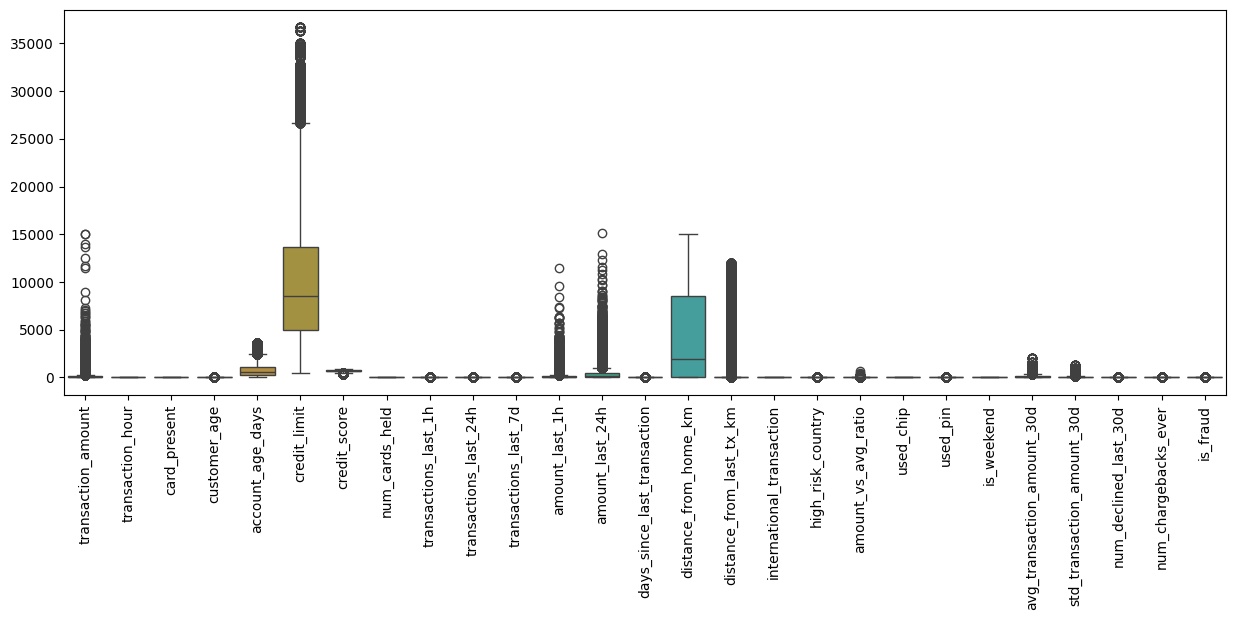

In [ ]:
plt.figure(figsize = (15,5))
sns.boxplot(data = df.select_dtypes(include = 'number'))
plt.xticks(rotation = 90)
plt.show()


In [ ]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, ":", len(outliers))

transaction_amount : 9959
transaction_hour : 0
card_present : 0
customer_age : 447
account_age_days : 4620
credit_limit : 1871
credit_score : 327
num_cards_held : 0
transactions_last_1h : 8990
transactions_last_24h : 3172
transactions_last_7d : 2801
amount_last_1h : 11150
amount_last_24h : 7925
days_since_last_transaction : 5002
distance_from_home_km : 0
distance_from_last_tx_km : 15617
international_transaction : 0
high_risk_country : 4932
amount_vs_avg_ratio : 11309
used_chip : 0
used_pin : 18387
is_weekend : 0
avg_transaction_amount_30d : 5870
std_transaction_amount_30d : 6113
num_declined_last_30d : 6019
num_chargebacks_ever : 22968
is_fraud : 2055


In [ ]:
df.groupby('is_fraud')[
    ['transaction_amount',
     'amount_last_1h',
     'amount_last_24h',
     'distance_from_last_tx_km',
     'num_chargebacks_ever']
].median()

,transaction_amount,amount_last_1h,amount_last_24h,distance_from_last_tx_km,num_chargebacks_ever
is_fraud,,,,,
0,52.06,0.0,197.26,13.3,0.0
1,64.80,0.0,221.94,16.4,0.0


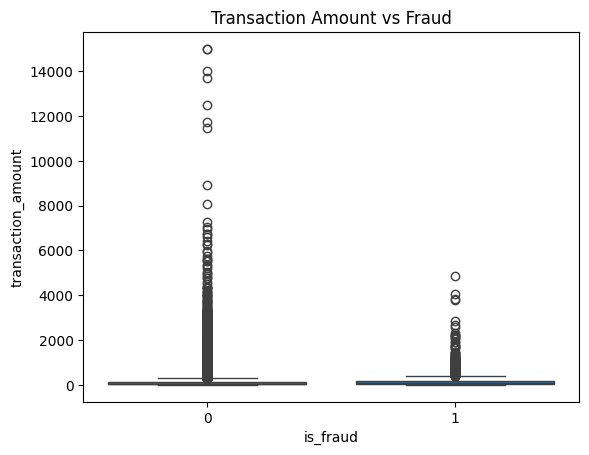

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(
    x='is_fraud',
    y='transaction_amount',
    data=df
)

plt.title('Transaction Amount vs Fraud')
plt.show()

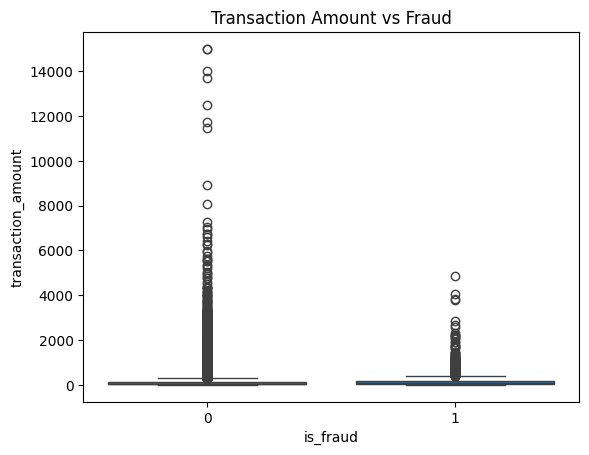

In [ ]:
sns.boxplot(
    x='is_fraud',
    y='transaction_amount',
    data=df
)

plt.title('Transaction Amount vs Fraud')
plt.show()

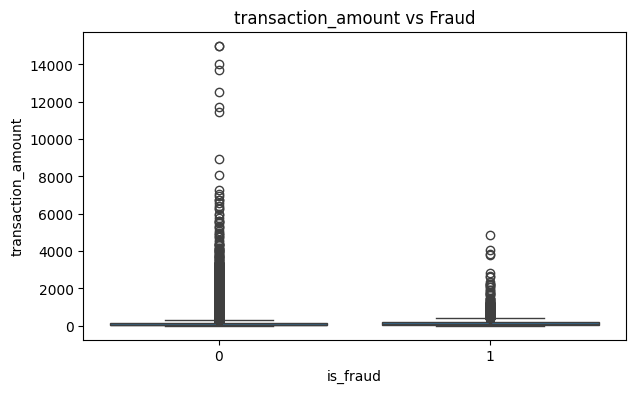

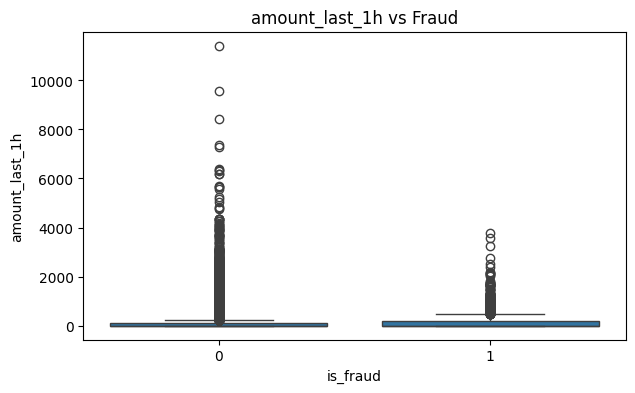

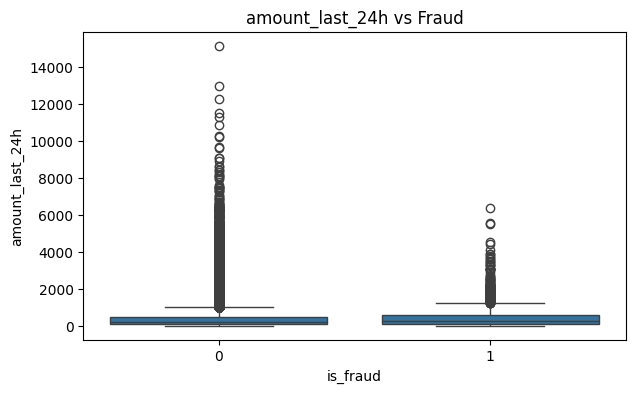

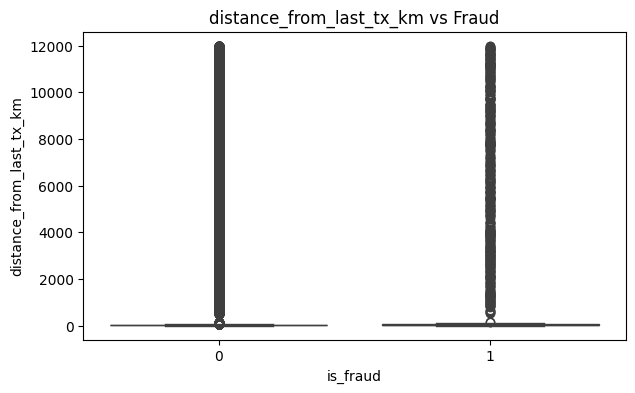

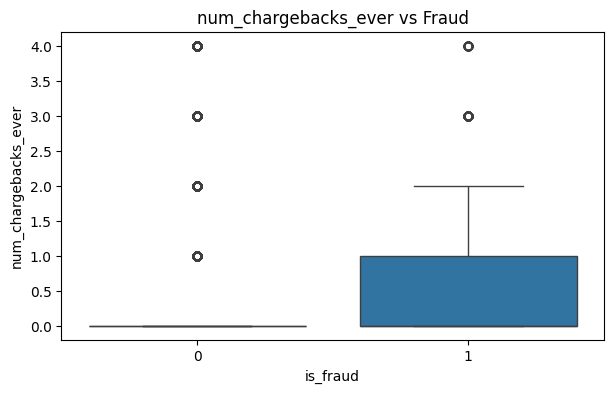

In [ ]:

cols = [
    'transaction_amount',
    'amount_last_1h',
    'amount_last_24h',
    'distance_from_last_tx_km',
    'num_chargebacks_ever'
]

for col in cols:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        x='is_fraud',
        y=col,
        data=df
    )

    plt.title(f'{col} vs Fraud')
    plt.show()

In [ ]:
# Outlier Treatment
df.columns = df.columns.str.strip();
columns = [
    'transaction_amount',
    'amount_last_1h',
    'amount_last_24h',
    'distance_from_last_tx_km'
]
for i in columns:
    Q1 = df[i].quantile(0.25)
    Q3 = df[i].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df[i] = np.where(df[i] < lower_bound , lower_bound, df[i])
    df[i] = np.where(df[i] > upper_bound, upper_bound , df[i])


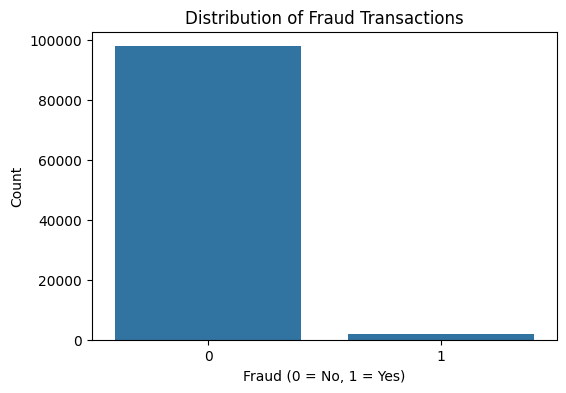

In [ ]:
# univariate Analysis
plt.figure(figsize=(6,4))

sns.countplot(data=df, x='is_fraud')

plt.title('Distribution of Fraud Transactions')
plt.xlabel('Fraud (0 = No, 1 = Yes)')
plt.ylabel('Count')

plt.show()

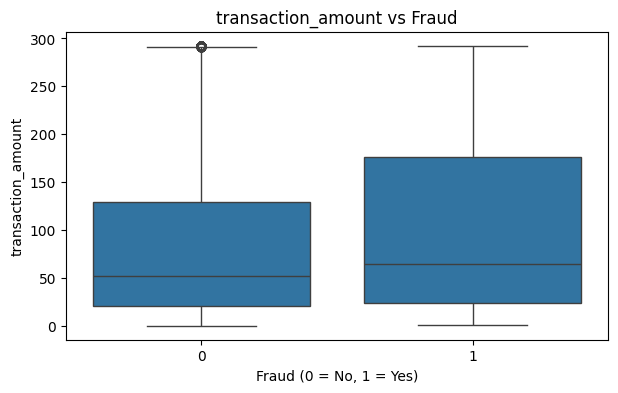

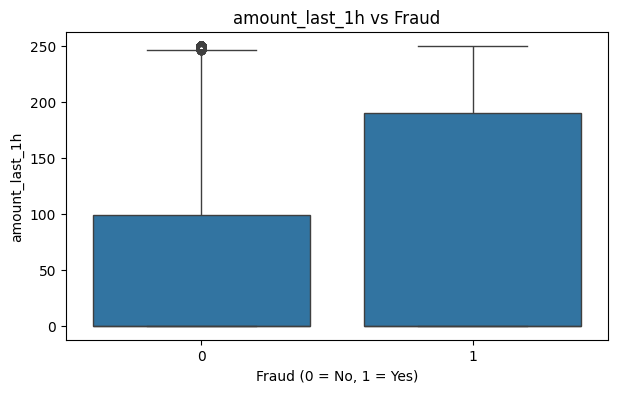

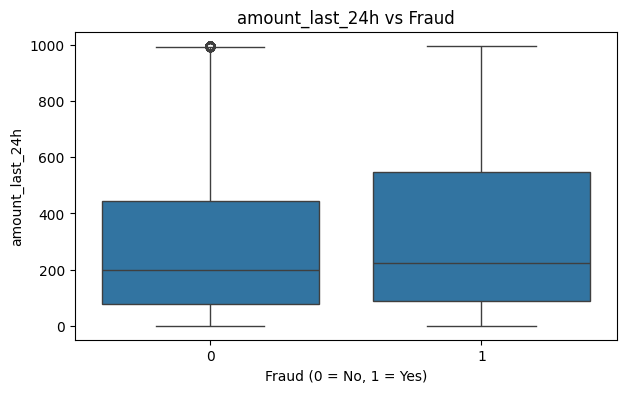

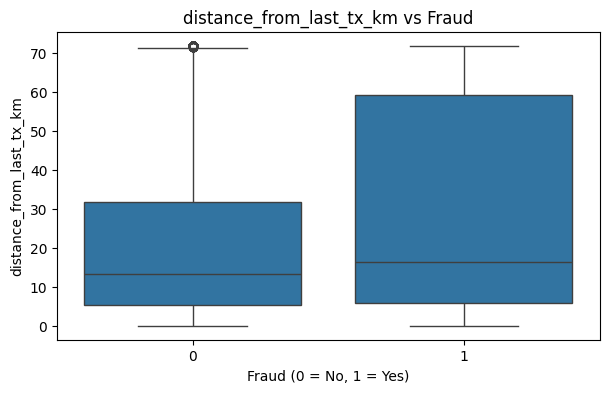

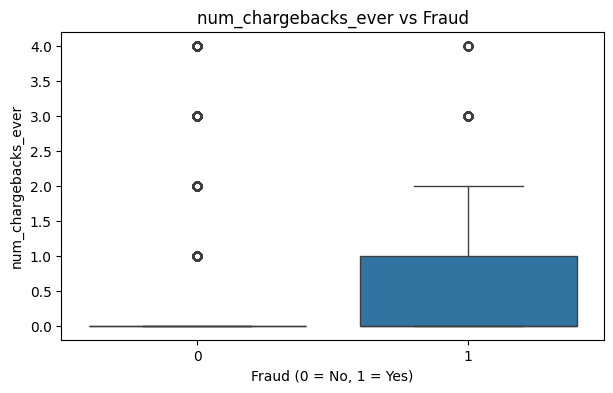

In [ ]:
# Bivariate Analysis
num_cols = [
    'transaction_amount',
    'amount_last_1h',
    'amount_last_24h',
    'distance_from_last_tx_km',
    'num_chargebacks_ever'
]
for col in num_cols:
  plt.figure(figsize=(7,4))
  sns.boxplot(data = df, x='is_fraud', y=col)
  plt.title(f'{col} vs Fraud')
  plt.xlabel('Fraud (0 = No, 1 = Yes)')
  plt.ylabel(col)
  plt.show()



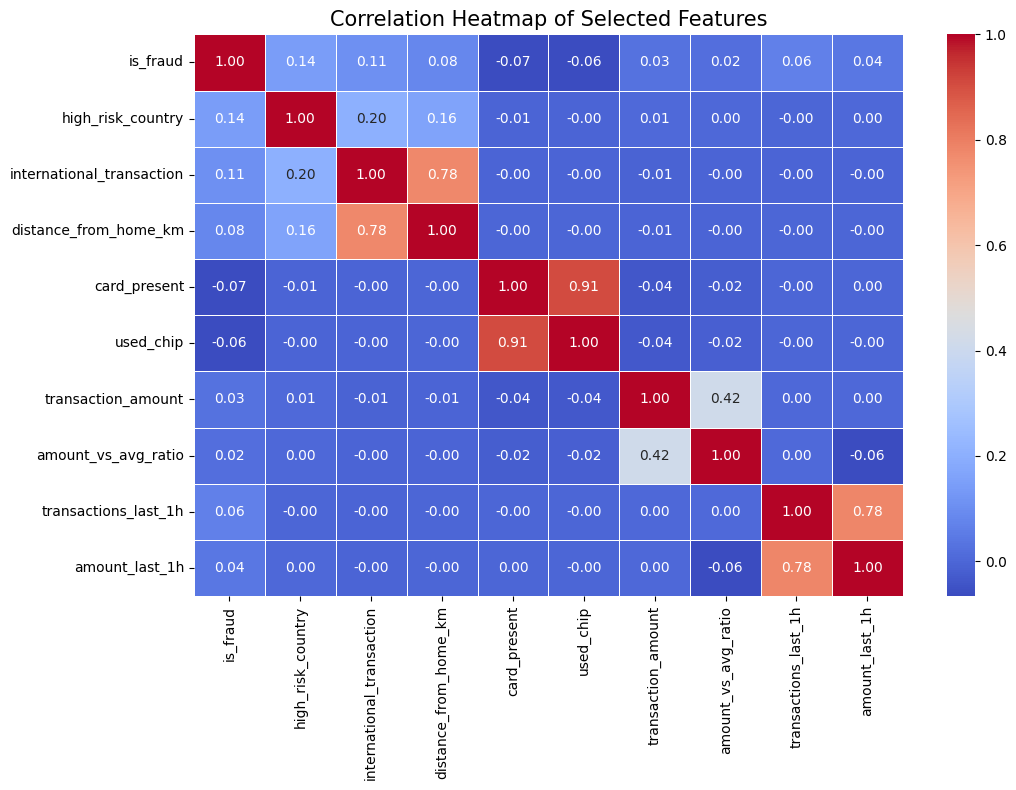

In [ ]:
selected_cols = [
    'is_fraud',
    'high_risk_country',
    'international_transaction',
    'distance_from_home_km',
    'card_present',
    'used_chip',
    'transaction_amount',
    'amount_vs_avg_ratio',
    'transactions_last_1h',
    'amount_last_1h'
]

corr = df[selected_cols].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    annot_kws={'size': 10}
)

plt.title('Correlation Heatmap of Selected Features', fontsize=15)
plt.tight_layout()
plt.show()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 36 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   transaction_amount           100000 non-null  float64
 1   merchant_category            100000 non-null  object 
 2   merchant_country             100000 non-null  object 
 3   transaction_hour             100000 non-null  int64  
 4   transaction_day_of_week      100000 non-null  object 
 5   card_present                 100000 non-null  int64  
 6   customer_age                 100000 non-null  int64  
 7   customer_gender              100000 non-null  object 
 8   customer_state               100000 non-null  object 
 9   account_age_days             100000 non-null  int64  
 10  credit_limit                 100000 non-null  float64
 11  credit_score                 100000 non-null  int64  
 12  num_cards_held               100000 non-null  int64  
 13  

In [ ]:
categorial_col = df.select_dtypes(include = 'object').columns
print(categorial_col)

Index(['merchant_category', 'merchant_country', 'transaction_day_of_week',
       'customer_gender', 'customer_state', 'transaction_channel',
       'device_type', 'browser', 'email_domain'],
      dtype='object')


In [ ]:
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include = 'object').columns:
  df[col] = df[col].str.strip()

In [ ]:
df.head()

,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,card_present,customer_age,customer_gender,customer_state,account_age_days,...,transaction_channel,device_type,browser,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,email_domain,is_fraud
0,37.36,Healthcare & Pharmacy,USA,2,Monday,0,41,Female,PA,709,...,Online,Mobile,Chrome,0,93.91,39.48,0,0,corporate,0
1,50.04,Restaurant & Dining,Germany,3,Monday,1,56,Male,WV,1143,...,In-store,POS Terminal,NaN,0,180.05,134.45,0,0,yahoo,0
2,38.87,Grocery & Supermarket,Australia,3,Monday,0,43,Male,MN,601,...,Online,Desktop,Chrome,0,42.00,22.46,0,0,hotmail,0
3,46.60,Gas Station,China,3,Monday,0,51,Female,OH,582,...,ATM,ATM,NaN,0,64.87,29.76,0,0,gmail,0
4,62.13,Clothing & Apparel,UK,4,Monday,1,40,Female,PA,711,...,In-store,POS Terminal,NaN,0,47.19,18.52,0,0,gmail,0


In [ ]:
df['browser'] = df['browser'].fillna('Unknown')

In [ ]:
df = pd.get_dummies(df, columns = categorial_col, drop_first= True, dtype = int)

In [ ]:
# Varifying Encoding
print(df.select_dtypes(include='object').columns)

Index([], dtype='object')


In [ ]:
df.head()

,transaction_amount,transaction_hour,card_present,customer_age,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,...,browser_Chrome,browser_Edge,browser_Firefox,browser_Other,browser_Safari,browser_Unknown,email_domain_gmail,email_domain_hotmail,email_domain_other,email_domain_yahoo
0,37.36,2,0,41,709,6630.0,742,2,1,2,...,1,0,0,0,0,0,0,0,0,0
1,50.04,3,1,56,1143,4350.0,602,1,6,6,...,0,0,0,0,0,1,0,0,0,1
2,38.87,3,0,43,601,3950.0,605,4,1,1,...,1,0,0,0,0,0,0,1,0,0
3,46.60,3,0,51,582,13870.0,675,5,0,2,...,0,0,0,0,0,1,1,0,0,0
4,62.13,4,1,40,711,6570.0,743,2,1,2,...,0,0,0,0,0,1,1,0,0,0


In [ ]:
#Sepreration Of variable
X = df.drop(columns = ['is_fraud'])
Y = df['is_fraud']

In [ ]:
# Train Test Split
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2,random_state = 42)

In [ ]:
print(df['is_fraud'].isnull().sum())
print(df['is_fraud'].value_counts(dropna=False))

0
is_fraud
0    97945
1     2055
Name: count, dtype: int64


In [ ]:
df = df.dropna(subset=['is_fraud'])

In [ ]:
# Model
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier()
model.fit(X_train,Y_train)

RandomForestClassifier()

In [ ]:
# prediction
y_prid = model.predict(X_test)

In [ ]:
print(y_prid[: 10])

[0 0 0 0 0 0 0 0 0 0]


In [ ]:
result = pd.DataFrame({'Actual' : Y_test, 'Predicted' : y_prid})
result.head(10)

,Actual,Predicted
75721,0,0
80184,0,0
19864,0,0
76699,0,0
92991,0,0
76434,0,0
84004,0,0
80917,0,0
60767,0,0
50074,0,0


In [ ]:
# Evaluation
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(Y_test, y_prid)
print("Accuracy:", accuracy)

Accuracy: 0.9797


In [ ]:
train_pred = model.predict(X_train)
train_accuracy = accuracy_score(Y_train, train_pred)
test_accuracy = accuracy_score(Y_test, y_prid)
print('Training Accuracy:', train_accuracy)
print('Testing Accuracy:', test_accuracy)

Training Accuracy: 0.9999875
Testing Accuracy: 0.9797


In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(Y_test, y_prid)
print(cm )

[[19594     0]
 [  406     0]]


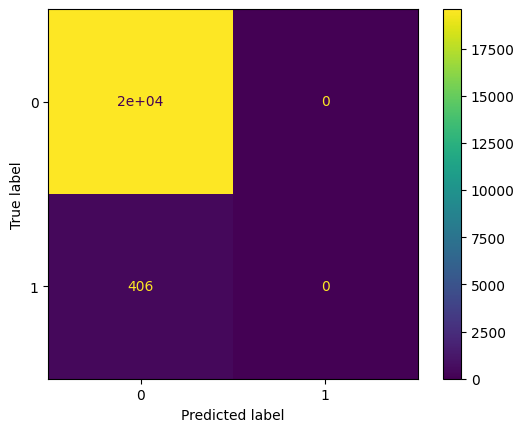

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot()
plt.show()

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(Y_test, y_prid))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99     19594
           1       0.00      0.00      0.00       406

    accuracy                           0.98     20000
   macro avg       0.49      0.50      0.49     20000
weighted avg       0.96      0.98      0.97     20000



In [ ]:
# HyperParameter Tuning
from sklearn.model_selection import GridSearchCV
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
grid = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, n_jobs = -1,verbose = 1)
grid.fit(X_train, Y_train)
best_params = grid.best_params_
print("Best Hyperparameters:", best_params)

Fitting 5 folds for each of 81 candidates, totalling 405 fits


KeyboardInterrupt: 

In [ ]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)
accuracy = accuracy_score(Y_test, y_pred)
print("Accuracy:", accuracy)